#Funciones necesarias para el funcionamiento del algoritmo

##Import de librerias y dataframe, preprocesado de los datos

In [ ]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import random
import itertools
import sys
from decimal import Decimal, ROUND_DOWN
from sklearn.preprocessing import LabelEncoder


import numpy as np
import math



In [ ]:
rm -r META

rm: cannot remove 'META': No such file or directory


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', 500)

# Creo mi DataFrame a partir del CSV proporcionado
df = pd.read_csv('data.csv', sep=';', index_col=0)
# Dataframe antiguo
# df = pd.read_csv('META/cleandata-2.csv)
print(df.info())

# Inicializo el LabelEncoder
label_encoder = LabelEncoder()

# Itero sobre las columnas del DataFrame
for col in df.columns:
    if df[col].dtype == 'object':  # Verifico si la columna es categórica
        df[col] = label_encoder.fit_transform(df[col])

# Elimino columnas con todos los valores NaN
df = df.dropna(axis=1, how='all')

print(df.head())


FileNotFoundError: [Errno 2] No such file or directory: 'data.csv'

##Codigo del profesor (Funcion para obtener el p_value)



In [ ]:
import numpy as np
import math

sizeN=40
sizeM=300
kendallN=0.5
kendallM=0.35

def get_p_value_normal(kendallN,kendallM,sizeN,sizeM):
	if kendallN == 1:
		a=math.inf
	elif kendallN == -1:
		a=-math.inf
	else:
		a=np.arctanh(kendallN)
	if kendallM == 1:
		b=math.inf
	elif kendallM == -1:
		b=-math.inf
	else:
		b=np.arctanh(kendallM)
	z = (a-b)/np.sqrt((1/(sizeN-3)) + (1/(sizeM-3)))
	z_value = abs(z)*2
	def get_cdf_normal(z_value):
		return 0.5 * (1 + math.erf(z_value / math.sqrt(2)))
	p_value = 1 - get_cdf_normal(abs(z_value))
	return p_value


## Funciones

In [ ]:

def ConsultarSolucion(df, solucion):
  new_df = pd.DataFrame(columns = df.columns)
  contador_genes_correctos = 0

  for index, row in df.iterrows():
    # Print the index label and values
    #print(f"Index label: {index}")
    for gen in solucion:
      variable = gen[0]
      rango = gen[1]
      #print("variable:", variable, " rango:", rango)
      #print("Valor de la variable ", variable, " :", df.at[index, df.columns[variable]])
      #Compruebo que la variable de la fila está en el rango determinado:
      if rango[0] < df.at[index, df.columns[variable]] < rango[1]:
        contador_genes_correctos = contador_genes_correctos + 1

      #Si la fila cumple con todas las restricciones de la solucion, la añado al nuevo df
    #if contador_genes_correctos == len(solucion):
      #print("Este individuo está dentro de los rangos de la solucion")
    contador_genes_correctos = 0
    #ARREGLAR ESTO

      #new_df = new_df.append(df.loc[index])
  return new_df


def mostrar_solucion_final(main_df,subset_df,sol_final):
  tau1 = 0
  tau2 = 0
  copia_df = subset_df.copy()
  copia_main_df = main_df.copy()
  condiciones = []
  pares_de_columnas = []
  p_value = 0
  p_value_medio = 0.0

  lista_valores_columna1 = []
  lista_valores_columna2 = []

  #Obtengo las restricciones impuestas por la solucion:
  for i in range(len(sol_final)):
    elemento_gen = sol_final[i]
    columna = elemento_gen[0]
    rango = elemento_gen[1]
    nombre = copia_df.columns[columna]
    agregar_condicion(condiciones,nombre,">=",rango[0])
    agregar_condicion(condiciones,nombre,"<=",rango[1])

  #Filtramos las filas que cumplan con las restricciones:
  subset_df_filtrado = aplicar_filtro(copia_df,condiciones)

  #Saco el df filtrado y su complementario
  main_df_filtrado, complementario_main_df_filtrado = obtener_main_df_filtrado(copia_main_df, subset_df_filtrado)
  #print(main_df_filtrado.shape)
  #print(complementario_main_df_filtrado.shape)
  #print(main_df.shape)
  #print("---------main_df_filtrado---------")
  #print(main_df_filtrado)
  #print("---------complementario_main_df_filtrado---------")

  #Si tenemos menos de cinco elementos devolvemos -1
  if(main_df_filtrado.shape[0] < 5):
    return -1

  pares_de_columnas = list(itertools.combinations(main_df_filtrado.columns, 2))
  #print(pares_de_columnas)

  #Para cada par de columnas calculo el los kendall y el p_value del par en si
  for par in pares_de_columnas:
    #Obtengo los valores de cada columna
    valores_columna1 = main_df_filtrado[par[0]].tolist()
    valores_columna2 = main_df_filtrado[par[1]].tolist()
    print("Valores de variables a comparar.")
    imprimir_grafica(valores_columna1,valores_columna2,par[0],par[1])
    #print("valores columna1: ", valores_columna1)
    #print("valores columna2: ", valores_columna2)
    #Obtengo los valores de cada columna en el complementario
    valores_columna1_complementario = complementario_main_df_filtrado[par[0]].tolist()
    valores_columna2_complementario = complementario_main_df_filtrado[par[1]].tolist()
    print("Valores de complementarios.")
    imprimir_grafica(valores_columna1_complementario,valores_columna2_complementario,par[0],par[1])


### Separación y filtrado del dataframe

In [ ]:

def agregar_condicion(condiciones, columna, operador, valor):
    condiciones.append(f"`{columna}` {operador} {valor}")

def aplicar_filtro(df, condiciones):
    filtro = " and ".join(condiciones)
    #print(filtro)  # Unir las condiciones con 'and'
    return df.query(filtro)

def separar_df(df,nombres_variables_a_comparar):
    df_main_variables = df[nombres_variables_a_comparar].copy()
    #print(df_main_variables)
    df_main_variables.dropna(inplace = True)
    # Ahora el dataframe que contiene las variables a comparar no tiene valores nulos
    #print(df_main_variables)
    indices_filas_eliminadas = df.index.difference(df_main_variables.index)
    df_subset_variables = df.drop(indices_filas_eliminadas)

    #Cambio para ver si funciona, en lugar de devolver un df_main de 2 columnas, lo devolvemos entero
    #df_main_variables = df.copy()

    return df_main_variables, df_subset_variables


def obtener_main_df_filtrado(df, subset_df_filtrado):

  indices_filtrados = subset_df_filtrado.index
  main_df_filtrado = df.loc[indices_filtrados]
  complementario_main_df_filtrado = df.drop(indices_filtrados)

  return main_df_filtrado, complementario_main_df_filtrado

def imprimir_grafica(col1,col2,n_col1,n_col2):

  plt.scatter(col1,col2)
  plt.xlabel(n_col1)
  plt.ylabel(n_col2)
  plt.show()

def adaptive_crossover(parent1, parent2, main_df, subset_df):
    # Determina la longitud mínima entre los dos padres
    min_length = min(len(parent1), len(parent2))

    # Selecciona un punto de cruce aleatorio basado en la longitud mínima
    crossover_point = random.randint(1, min_length - 1)

    # Crea los descendientes
    offspring1 = parent1[:crossover_point] + parent2[crossover_point:]

    return offspring1

###Funcion de Fitness

In [ ]:
def FuncionFitness(main_df, subset_df, individuo):
  tau1 = 0
  tau2 = 0
  copia_df = subset_df.copy()
  copia_main_df = main_df.copy()
  condiciones = []
  pares_de_columnas = []
  p_value = 0
  p_value_medio = 0.0

  lista_valores_columna1 = []
  lista_valores_columna2 = []

  #Obtengo las restricciones impuestas por la solucion:
  for i in range(len(individuo)):
    elemento_gen = individuo[i]
    columna = elemento_gen[0]
    rango = elemento_gen[1]
    nombre = copia_df.columns[columna]
    agregar_condicion(condiciones,nombre,">=",rango[0])
    agregar_condicion(condiciones,nombre,"<=",rango[1])

  #Filtramos las filas que cumplan con las restricciones:
  subset_df_filtrado = aplicar_filtro(copia_df,condiciones)

  #Saco el df filtrado y su complementario
  main_df_filtrado, complementario_main_df_filtrado = obtener_main_df_filtrado(copia_main_df, subset_df_filtrado)
  #print(main_df_filtrado.shape)
  #print(complementario_main_df_filtrado.shape)
  #print(main_df.shape)
  #print("---------main_df_filtrado---------")
  #print(main_df_filtrado)
  #print("---------complementario_main_df_filtrado---------")

  #Si tenemos menos de cinco elementos devolvemos -1
  if(main_df_filtrado.shape[0] < 5):
    return -1

  pares_de_columnas = list(itertools.combinations(main_df_filtrado.columns, 2))
  #print(pares_de_columnas)

  #Para cada par de columnas calculo el los kendall y el p_value del par en si
  for par in pares_de_columnas:
    #Obtengo los valores de cada columna
    valores_columna1 = main_df_filtrado[par[0]].tolist()
    valores_columna2 = main_df_filtrado[par[1]].tolist()
    #print("valores columna1: ", valores_columna1)
    #print("valores columna2: ", valores_columna2)
    #Obtengo los valores de cada columna en el complementario
    valores_columna1_complementario = complementario_main_df_filtrado[par[0]].tolist()
    valores_columna2_complementario = complementario_main_df_filtrado[par[1]].tolist()
    #print("valores complementario 1: ", valores_columna1_complementario)
    #print("valores complementario 2: ", valores_columna2_complementario)
    #Calculo el coeficiente de kendall el par y en su complementario
    tau1, pvalor1 = stats.kendalltau(valores_columna1, valores_columna2)
    tau2, pvalor2 = stats.kendalltau(valores_columna1_complementario, valores_columna2_complementario)
    #print("Tau1: ", tau1)
    #print("Tau2: ", tau2)
    #Calculo el p_value del subgrupo con su complementario y lo sumo a la media
    p_value_medio = p_value_medio + get_p_value_normal(tau1,tau2,len(valores_columna1),len(valores_columna1_complementario))
    #Divido la suma de los p_values entre el numero de variables para obtener la media de los p_values
    p_value_medio = p_value_medio / len(pares_de_columnas)
    #print("p_value_medio = ", p_value_medio)

  return p_value_medio

In [ ]:
variables_a_comparar = [ random.randint(1, 300),random.randint(1, 300),random.randint(1, 300)]
nombres_variables_a_comparar = []

for i in variables_a_comparar:
  nombres_variables_a_comparar.append(df.columns[i])

print("Variables a comparar : ", nombres_variables_a_comparar)
main_df, subset_df = separar_df(df,nombres_variables_a_comparar)

solucion = SolucionAleatoria(main_df,subset_df)
print(solucion)

error_solucion = FuncionFitness(main_df, subset_df, solucion)
print(error_solucion)

NameError: name 'df' is not defined

##Algoritmo evolutivo

###Representacion de la solucion y generación de soluciones aleatorias


Cada gen de la solucion contiene como primer elemento el indice de la variable que restringe y como segundo elemento el rango de valores que acepta

In [ ]:
#Ejemplo:
solucion1 = [[1, [0,100]], [2, [0,100]], [3, [0,100]]]

def SolucionAleatoria(main_df, df_subset):
  min = 1
  max = 6
  rand_sol = []
  rand_sol_size = random.randint(min, max)
  error = -1
  while error == -1:
    rand_sol = []
    for i in range(rand_sol_size):
      variable = random.randint(0, df_subset.shape[1] - 1)
      min_val = np.nanmin(df_subset.iloc[:,variable])
      max_val = np.nanmax(df_subset.iloc[:,variable])

      while math.isnan(min_val) or math.isnan(max_val):
        variable = random.randint(0, df_subset.shape[1] - 1)
        min_val = np.nanmin(df_subset.iloc[:,variable])
        max_val = np.nanmax(df_subset.iloc[:,variable])

      if(min_val != max_val):
        min_aleatorio = np.random.randint(min_val,max_val+1)
        max_aleatorio = np.random.randint(min_val,max_val+1)
        while(min_aleatorio == max_aleatorio):
          min_aleatorio = np.random.randint(min_val,max_val+1)
          max_aleatorio = np.random.randint(min_val,max_val+1)
        if(min_aleatorio > max_aleatorio):
          min_aleatorio,max_aleatorio = max_aleatorio,min_aleatorio
        min_val,max_val = min_aleatorio, max_aleatorio
      rango=[min_val,max_val]
      gen = [variable, rango]
      rand_sol.append(gen)
    error = FuncionFitness(main_df, df_subset ,rand_sol)

  return rand_sol

###Operadores de cruce


Aqui están definidos tanto los operadores de cruce que hemos ideado pero descartado como el operador que hemos usado al final.

In [ ]:
def operadorGenticoRandomHalgFromParents(padre1, padre2, main_df, subset_df):
  hijo = []
  fitness = -1
  for gen in padre1:
    hijo.append(gen)

  for gen in padre2:
    hijo.append(gen)

  longitud_hijo = math.ceil(len(hijo) / 2)
  hijo = random.sample(hijo, longitud_hijo)
  fitness = FuncionFitness(main_df, subset_df, hijo)
  return padre1
  #return hijo

In [ ]:
def alternating_crossover(parent1, parent2, main_df, subset_df):

    offspring = []
    min_length = min(len(parent1), len(parent2))

    for i in range(min_length):
        offspring.append(parent1[i])
        offspring.append(parent2[i])
    if len(parent1) > min_length:
        offspring.extend(parent1[min_length:])
    if len(parent2) > min_length:
        offspring.extend(parent2[min_length:])

    offspring = random.sample(offspring, min(len(parent1), len(parent2)))

    return offspring

In [ ]:
def Custom_Crossover(padre1, padre2, main_df, subset_df):
  hijo = []
  fitness = -1
  if(len(padre1) == len(padre2) & len(padre1) == 1):
    hijo = padre1 + padre2
  else:
    for gen in padre1:
      hijo.append(gen)

    for gen in padre2:
      hijo.append(gen)

    longitud_hijo = math.ceil(len(hijo) / 2)
    hijo = random.sample(hijo, longitud_hijo)
    fitness = FuncionFitness(main_df, subset_df, hijo)

  while fitness == -1:
    hijo = []
    for gen in padre1:
      hijo.append(gen)
    for gen in padre2:
      hijo.append(gen)

    longitud_hijo = math.ceil(len(hijo) / 2)
    hijo = random.sample(hijo, longitud_hijo)
    fitness = FuncionFitness(main_df, subset_df, hijo)

  return hijo

In [ ]:
def custom_alternating_crossover(parent1, parent2, main_df, subset_df):

    offspring = []
    min_length = min(len(parent1), len(parent2))

    if(len(parent1) == 1 and len(parent2) == 1):
      offspring.append(parent1[0])
      offspring.append(parent2[0])
    else:
      for i in range(min_length):
          offspring.append(parent1[i])
          offspring.append(parent2[i])
      if len(parent1) > min_length:
          offspring.extend(parent1[min_length:])
      if len(parent2) > min_length:
          offspring.extend(parent2[min_length:])

      offspring = random.sample(offspring, min(len(parent1), len(parent2)))

    return offspring

###Operadores de mutacion

Este operador se encargará de mutar cada gen de una variable con una probilidad definida por el usuario, cuando se da la mutación, el gen será sustituido por otro completamente nuevo

In [ ]:
import random
import numpy as np

def operadorMutacionGenTotalmenteNuevo(individuo, p_mutacion, subset_df):
    if random.random() < p_mutacion:
        print("Se ha aplicado mutacion")
        individuoMutado = individuo
        # Elegir un gen al azar
        gen_idx = random.randint(0, len(individuoMutado) - 1)
        gen = individuoMutado[gen_idx]
        print("gen mutado: ", gen)
        col_idx = gen[0]
        min_val = subset_df.iloc[:, col_idx].min()
        max_val = subset_df.iloc[:, col_idx].max()

        if isinstance(min_val, (int, np.integer)) and isinstance(max_val, (int, np.integer)):
            if min_val == max_val:
                minimo = maximo = min_val
            else:
                minimo = random.randint(min_val, max_val - 1)
                maximo = random.randint(minimo + 1, max_val)
        else:
            if min_val == max_val:
                minimo = maximo = min_val
            else:
                minimo = random.uniform(min_val, max_val)
                maximo = random.uniform(minimo, max_val)

        gen[1] = [minimo, maximo]
    else:
        individuoMutado = individuo
    return individuoMutado


In [ ]:
def operadorMutacionGenTotalmenteNuevo(individuo, p_mutacion, subset_df):
  individuo_mutado = individuo
  valor_aleatorio = random.random()
  if valor_aleatorio < p_mutacion:
  # Elegir un gen al azar
    gen_idx = random.randint(0, len(individuo_mutado) - 1)
    gen = individuo_mutado[gen_idx]
    gen_antiguo = gen
    variable = random.randint(0, subset_df.shape[1] - 1)
    min_val = np.nanmin(subset_df.iloc[:,variable])
    max_val = np.nanmax(subset_df.iloc[:,variable])

    while math.isnan(min_val) or math.isnan(max_val):
      variable = random.randint(0, subset_df.shape[1] - 1)
      min_val = np.nanmin(subset_df.iloc[:,variable])
      max_val = np.nanmax(subset_df.iloc[:,variable])

    if(min_val != max_val):
      min_aleatorio = np.random.randint(min_val,max_val+1)
      max_aleatorio = np.random.randint(min_val,max_val+1)
      while(min_aleatorio == max_aleatorio):
        min_aleatorio = np.random.randint(min_val,max_val+1)
        max_aleatorio = np.random.randint(min_val,max_val+1)
      if(min_aleatorio > max_aleatorio):
        min_aleatorio,max_aleatorio = max_aleatorio,min_aleatorio
        min_val,max_val = min_aleatorio, max_aleatorio
      rango=[min_val,max_val]
      gen = [variable, rango]

    individuo_mutado[gen_idx] = gen
    #print("gen mutado: ", gen_antiguo, "gen nuevo:", gen, "p_mutacion:", p_mutacion, "valor aleatorio:", valor_aleatorio)

  return individuo_mutado

###Operador de Torneo

Operadore que seleccionará los dos padres para posteriormente aplicar el cruce, estos serán seleccionados mediante un torneo, eligiendo n indiviudos aleatorios, el que tenga mejor valor de fitness será el ganador y seleccionado como padre

In [ ]:
def AplicarTorneo(poblacion,TamañoTorneo, main_df, subset_df):
    ganador = []
    # Seleccionar participantes únicos para el torneo
    #print("Tamaño torneo: ", TamañoTorneo, "Tamaño Poblacio: ", len(poblacion))
    participantes = random.sample(poblacion, TamañoTorneo)
    MejorError = float('-inf')  # Inicializar con el peor valor posible

    for individuo in participantes:
        error_actual = FuncionFitness(main_df, subset_df, individuo)
        if error_actual >= MejorError:
            ganador = individuo
            MejorError = error_actual

    return ganador

###Buscar la mejor solucion en una poblacion

In [ ]:
def EncontrarMejorSolucion(main_df, subset_df, poblacion):
  MejorError = float(-1)
  MejorSolucion = []

  for individuo in poblacion:
    MejorError = FuncionFitness(main_df,subset_df,individuo)
    if(MejorError <= MejorError):
      MejorSolucion = individuo


  return MejorSolucion, MejorError

###Algoritmo evolutivo

In [ ]:
def AlgoritmoEvolutivo(TamañoPoblacion, NumeroGeneraciones, ProbabilidadMutacion, TamañoTorneo, main_df, subset_df):
    Poblacion = []
    # Genero una poblacion de soluciones aleatorias
    for i in range(TamañoPoblacion -1):
        Poblacion.append(SolucionAleatoria(main_df, subset_df))
        print("Solucion ", i + 1, " : ", Poblacion[i])
    mejorSolucion = SolucionAleatoria(main_df, subset_df)
    Poblacion.append(mejorSolucion)
    print("Solucion ", TamañoPoblacion, " : ", mejorSolucion)
    mejorError = -1
    # Modelo generacional:
    for i in range(NumeroGeneraciones):
        print("\n\nGENERACION: ", i + 1, "-------------------------------------------------------------------------------------\n\n")
        NuevaPoblacion = []  # Incluir la mejor solución en la nueva población
        # Aplicar Torneo para elegir a los padres y generar hijos
        for j in range(len(Poblacion)):
            padre1 = AplicarTorneo(Poblacion, TamañoTorneo, main_df, subset_df)
            padre2 = AplicarTorneo(Poblacion, TamañoTorneo, main_df, subset_df)
            # Aplicar operadores de Cruce
            hijo = operadorGenticoRandomHalgFromParents(padre1, padre2, main_df, subset_df)
            # Aplicar operadores de Mutacion al hijo generado
            hijo = operadorMutacionGenTotalmenteNuevo(hijo, ProbabilidadMutacion, subset_df)
            fitness = FuncionFitness(main_df, subset_df, hijo)
            if fitness > mejorError:
                mejorSolucion = hijo
                mejorError = fitness
            NuevaPoblacion.append(hijo)
            print(j + 1, ":", fitness, hijo, "Mejor solucion: ", mejorSolucion, mejorError)
        # Actualizar la población con la nueva población (incluyendo la mejor solución)
        Poblacion = NuevaPoblacion
    # Al finalizar todas las generaciones, mostrar la mejor solución encontrada
    print("Mejor Solucion: ", mejorSolucion, " Error: ", mejorError)
    return mejorSolucion


#EJECUCION CON PARAMETROS POR DEFECTO

Esta celda la hemos dedicado a hacer pruebas, comprobar que funciona el algortimo y ajustar los parámetros para buscar nuevas soluciones, hemos comprobado que obtenemos soluciones de mucha mejor calidad cuando elegimos solo dos variables a comparación de cuando se eligen tres.

variables seleccionadas:  ['freedom', 'power']
Solucion  1  :  [[4, [4, 10]], [42, [1, 2]], [15, [0, 1]], [50, [91, 441]], [14, [0, 1]], [8, [0, 1]], [22, [2, 3]]]
Solucion  2  :  [[32, [1, 10]], [7, [0, 1]], [5, [3, 10]], [47, [265, 26540]], [21, [0, 2]], [10, [0, 1]], [29, [1, 5]], [0, [0, 4]], [34, [0, 4]], [21, [2, 3]]]
Solucion  3  :  [[38, [1, 6]], [29, [3, 7]], [53, [5608, 10349]]]
Solucion  4  :  [[9, [0, 1]], [29, [3, 5]], [14, [0, 1]]]
Solucion  5  :  [[2, [1, 2]], [46, [7739, 15306]], [42, [1, 2]], [16, [0, 1]], [10, [0, 1]], [20, [1, 5]], [45, [14200, 26210]]]
Solucion  6  :  [[21, [2, 5]], [2, [1, 2]], [45, [9303, 15076]], [52, [29, 34]], [5, [4, 10]]]
Solucion  7  :  [[9, [0, 1]], [37, [24, 33]], [35, [1, 7]], [11, [0, 1]], [20, [1, 2]]]
Solucion  8  :  [[46, [18125, 23206]], [1, [3, 5]]]
Solucion  9  :  [[29, [5, 7]], [48, [14131, 17115]], [8, [0, 1]], [30, [4, 6]], [42, [0, 2]], [50, [126, 366]]]
Solucion  10  :  [[11, [0, 1]], [49, [825, 4284]], [29, [1, 3]]]
Solucion 

<ipython-input-8-120ca4cacf4d>:22: RuntimeWarning: invalid value encountered in sqrt
  z = (a-b)/np.sqrt((1/(sizeN-3)) + (1/(sizeM-3)))


1 : 0.06350906521985666 [[15, [0, 1]], [34, [0, 6]], [37, [30, 45]], [11, [0, 1]], [20, [1, 3]], [44, [181, 1125]], [42, [0, 1]], [1, [2, 4]], [7, [0, 1]], [22, [1, 6]]] Mejor solucion:  [[15, [0, 1]], [34, [0, 6]], [37, [30, 45]], [11, [0, 1]], [20, [1, 3]], [44, [181, 1125]], [42, [0, 1]], [1, [2, 4]], [7, [0, 1]], [22, [1, 6]]] 0.06350906521985666
2 : 0.37627373395431907 [[5, [1, 3]], [20, [0, 2]], [10, [0, 1]], [33, [2, 8]], [15, [0, 1]], [39, [15, 29]], [29, [1, 3]], [36, [3, 4]]] Mejor solucion:  [[5, [1, 3]], [20, [0, 2]], [10, [0, 1]], [33, [2, 8]], [15, [0, 1]], [39, [15, 29]], [29, [1, 3]], [36, [3, 4]]] 0.37627373395431907
3 : 0.3744732745042735 [[23, [2, 4]], [26, [4, 7]], [21, [1, 3]], [42, [0, 1]], [21, [1, 5]], [35, [5, 7]], [20, [0, 4]], [41, [4, 6]], [33, [7, 10]], [48, [14812, 24058]]] Mejor solucion:  [[5, [1, 3]], [20, [0, 2]], [10, [0, 1]], [33, [2, 8]], [15, [0, 1]], [39, [15, 29]], [29, [1, 3]], [36, [3, 4]]] 0.37627373395431907
4 : 0.3744732745042735 [[23, [2, 4

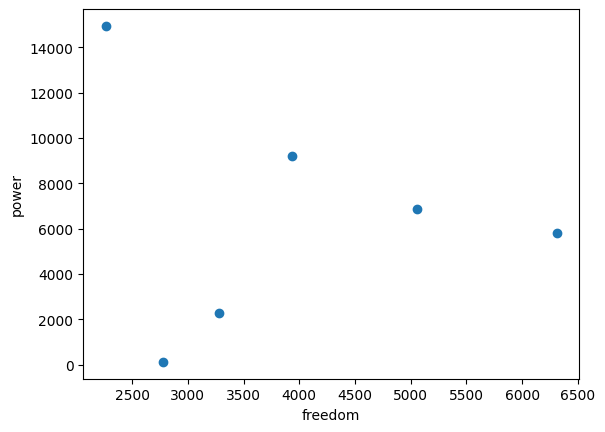

Valores de complementarios.


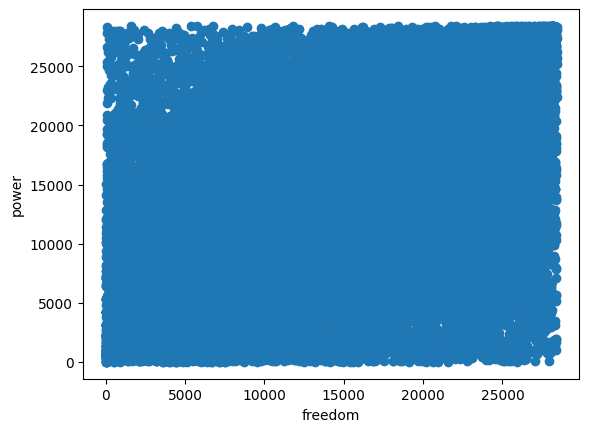

In [ ]:
#Pues añadir aqui la ejecucion que vayamos a hacer
NumeroGeneraciones = 8
TamañoTorneo = 5
ProbabilidadMutacion = 0.1
TamañoPoblacion = 30

variables  = [47, 48]
nombres_variables=[]
numeroVar = len(variables)
var_nombre = []
for i in variables:
  var_nombre.append(df.columns[i])
print("variables seleccionadas: ", var_nombre)

main_df,subset_df = separar_df(df,var_nombre)


#Ejecutar Algoritmo Evolutivo y mostrar resultado:
mejorSolucion = []
#Descomentar la siguiente linea para ejecutar el algoritmo con los parametros por defecto:
mejorSolucion = AlgoritmoEvolutivo(TamañoPoblacion, NumeroGeneraciones, ProbabilidadMutacion, TamañoTorneo, main_df, subset_df)
mostrar_solucion_final(main_df,subset_df,mejorSolucion)


#EJECUCION FINAL (PROFESOR)

In [ ]:
#Pido el numero de variables
numeroVar = int(input("Ingrese un número de variables que quiere seleccionar: "))
#Bucle for recibiendo el numero de variables
variables = []
nombres_variables=[]

if(numeroVar > 1):
  for i in range(numeroVar):
    variable = int(input("Ingrese el índice de la variable: "))
    variables.append(variable)
  print("variables seleccionadas: ", variables)

  nombres_variables=[]
  numeroVar = len(variables)
  var_nombre = []
  for i in variables:
    var_nombre.append(df.columns[i])
  print("variables seleccionadas: ", var_nombre)

  main_df,subset_df = separar_df(df,var_nombre)


  #Pido los parámetros
  TamañoPoblacion = int(input("Seleccionar el tamaño de la población : "))
  NumeroGeneraciones = int(input("Seleccione el numero de generaciones: "))
  TamañoTorneo = int(input("Seleccione el tamaño del torneo "))
  ProbabilidadMutacion = float(input("Seleccione la probabilidad de mutacion: "))

  # Devuelve la mejor solución despues de realizar todas las generaciones
  mejorSolucion = []
  mejorSolucion = AlgoritmoEvolutivo(TamañoPoblacion, NumeroGeneraciones,ProbabilidadMutacion,  TamañoTorneo, main_df, subset_df)

  #Muestro esta mejor solucion junto a su fitness:
  mostrar_solucion_final(main_df,subset_df,mejorSolucion)

else:
  print("Debe elegir un número de variables mayor que 1")

#Ejecuto el algoritmo evolutivo y muestro el resultado

Ingrese un número de variables que quiere seleccionar: 2
